# LAB01 — Prompt Anatomy

## Amac

Bu lab, farkli prompt yapilarinin ayni siniflandirma gorevi uzerindeki etkisini
karsilastirmali olarak incelemek icin tasarlanmistir. Groq API uzerinden gercek
LLM cagrilari yaparak dort farkli prompt varyasyonunun; dogruluk (accuracy),
cikti format uyumu, token kullanimi ve gecikme (latency) uzerindeki etkisini
olceriz.

## Hipotez

> **Daha fazla prompt bileseni, her zaman daha yuksek performans anlamina gelmez.**

Bu lab boyunca dort deney calistiracagiz:

| Deney | Icerik |
|---|---|
| `E01_baseline` | Sadece instruction |
| `E02_context_constraints` | Instruction + context + constraints |
| `E03_output_contract` | Onceki bilesenler + kesin cikti formati |
| `E04_few_shot` | Onceki bilesenler + few-shot ornekler |

Gorev: Hayali bir elektronik sirketinin musteri destek mesajlarini
`billing`, `technical_issue`, `cancellation`, `complaint`, `general_inquiry`
kategorilerinden birine ve `low`/`medium`/`high` oncelik seviyesine atamak.

**Not:** Bu notebook acildiginda hicbir ucretli API cagrisi otomatik olarak
yapilmaz. Gercek cagrilar yalnizca `RUN_LIVE = True` yapildiginda gerceklesir.


## Step 2 — Kutuphaneleri Ice Aktar

In [1]:
import os
import json
import time
import re
from pathlib import Path

import tomli
import yaml
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from groq import Groq

load_dotenv()

print("Kutuphaneler basariyla yuklendi.")


Kutuphaneler basariyla yuklendi.


## Step 3 — Yapilandirmayi Yukle

Model parametrelerini `config/settings.toml` dosyasindan, prompt
varyasyonlarini `config/prompts.yaml` dosyasindan okuyoruz. Bu degerleri
notebook icerisinde tekrar hardcode etmiyoruz; egitim sirasinda katilimcilar
bu dosyalari degistirerek davranisi kolayca gorebilir.

API key, guvenlik nedeniyle burada hicbir sekilde goruntulenmez.


In [2]:
CWD = Path.cwd()
PROJECT_ROOT = CWD if (CWD / "config").exists() else CWD.parent

with open(PROJECT_ROOT / "config" / "settings.toml", "rb") as f:
    settings = tomli.load(f)

with open(PROJECT_ROOT / "config" / "prompts.yaml", "r", encoding="utf-8") as f:
    prompts_config = yaml.safe_load(f)

MODEL_NAME = settings["model"]["name"]
MODEL_TEMPERATURE = settings["model"]["temperature"]
MODEL_MAX_TOKENS = settings["model"]["max_completion_tokens"]
MAX_CASES = settings["experiment"]["max_cases"]
REPETITIONS = settings["experiment"]["repetitions"]

print("Model ayarlari:")
print(f"  provider               : {settings['model']['provider']}")
print(f"  name                   : {MODEL_NAME}")
print(f"  temperature            : {MODEL_TEMPERATURE}")
print(f"  max_completion_tokens  : {MODEL_MAX_TOKENS}")
print()
print("Deney ayarlari:")
print(f"  max_cases              : {MAX_CASES}")
print(f"  repetitions            : {REPETITIONS}")


Model ayarlari:
  provider               : groq
  name                   : openai/gpt-oss-20b
  temperature            : 0.0
  max_completion_tokens  : 512

Deney ayarlari:
  max_cases              : 5
  repetitions            : 1


## Step 4 — Veri Setini Yukle

`data/messages.json` icerisindeki 15 sentetik Turkce musteri destek mesajini
Pandas DataFrame'e yukluyoruz. Her mesajin beklenen kategorisi
(`expected_label`) ve beklenen oncelik seviyesi (`expected_priority`) onceden
etiketlenmistir.


In [3]:
with open(PROJECT_ROOT / "data" / "messages.json", "r", encoding="utf-8") as f:
    messages_data = json.load(f)

df_messages = pd.DataFrame(messages_data)
print(f"Toplam mesaj sayisi: {len(df_messages)}")
df_messages.head(15)


Toplam mesaj sayisi: 15


,id,message,expected_label,expected_priority
0,1,"Son faturamda yanlis ucretlendirme var, 2 kat ...",billing,medium
1,2,Gecen ay odedigim tutar ile fatura detayinda y...,billing,low
2,3,Kredi kartimdan iki kere ayni tutarda cekim ya...,billing,high
3,4,"Yeni aldigim kulaklik hic sarj almiyor, kutuda...",technical_issue,high
4,5,Akilli saatim bazen ekranini kilitliyor ve yen...,technical_issue,medium
5,6,Bluetooth hoparlorumu telefonuma baglarken baz...,technical_issue,low
6,7,Gecen hafta siparis ettigim tableti iptal etme...,cancellation,medium
7,8,Yillik bakim aboneligimi iptal etmek istiyorum...,cancellation,low
8,9,"Siparisimi yanlis verdigimi fark ettim, hemen ...",cancellation,high
9,10,Magazanizdan aldigim laptop bir haftada iki ke...,complaint,high


## Step 5 — Prompt Varyasyonlarini Tanimla

`config/prompts.yaml` icerisindeki bilesenleri (`instruction`, `context`,
`constraints`, `output_format`, `few_shot_examples`) her deney icin dogru
sirada birlestiren basit bir fonksiyon yaziyoruz. Few-shot ornekleri,
degerlendirme veri setindeki mesajlardan farklidir.


In [4]:
def format_few_shot_examples(examples):
    blocks = []
    for i, example in enumerate(examples, start=1):
        block = (
            f"Ornek {i}:\n"
            f"Mesaj: \"{example['message']}\"\n"
            f"ETIKET: {example['label']}\n"
            f"ONCELIK: {example['priority']}"
        )
        blocks.append(block)
    return "\n\n".join(blocks)


def build_prompt(experiment_key):
    experiment = prompts_config["experiments"][experiment_key]
    parts = []
    for component in experiment["components"]:
        if component == "few_shot_examples":
            parts.append(format_few_shot_examples(prompts_config["few_shot_examples"]))
        else:
            parts.append(prompts_config[component].strip())
    return "\n\n".join(parts)


def build_full_prompt(experiment_key, customer_message):
    base_prompt = build_prompt(experiment_key)
    return f'{base_prompt}\n\nMusteri Mesaji: "{customer_message}"'


EXPERIMENT_KEYS = list(prompts_config["experiments"].keys())
print("Tanimli deneyler:", EXPERIMENT_KEYS)


Tanimli deneyler: ['E01_baseline', 'E02_context_constraints', 'E03_output_contract', 'E04_few_shot']


In [5]:
# Her deneyin olusturdugu prompt'u inceleyelim
for key in EXPERIMENT_KEYS:
    print(f"===== {key} ({prompts_config['experiments'][key]['name']}) =====")
    print(build_prompt(key))
    print()


===== E01_baseline (E01 - Baseline) =====
Sen bir elektronik sirketinin musteri destek mesajlarini siniflandiran bir asistansin.
Verilen musteri mesajini oku ve kategorisini ile oncelik seviyesini belirle.

===== E02_context_constraints (E02 - Context + Constraints) =====
Sen bir elektronik sirketinin musteri destek mesajlarini siniflandiran bir asistansin.
Verilen musteri mesajini oku ve kategorisini ile oncelik seviyesini belirle.

Sirket, elektronik urunler satan ve musteri destegi saglayan bir e-ticaret platformudur.
Musteriler fatura sorunlari, teknik arizalar, iptal talepleri, sikayetler ve genel sorular icin
destek hattina yazmaktadir.

Kurallar:
- Kategori sadece su bes degerden biri olabilir: billing, technical_issue, cancellation, complaint, general_inquiry
- Oncelik sadece su uc degerden biri olabilir: low, medium, high
- Baska hicbir aciklama veya yorum ekleme.

===== E03_output_contract (E03 - Output Contract) =====
Sen bir elektronik sirketinin musteri destek mesajlarini 

## Step 6 — Groq Client'i Baslat

`RUN_LIVE` degiskeni `False` oldugu surece hicbir gercek API cagrisi
yapilmaz. Egitmen veya katilimci bu degeri bilinçli olarak `True` yaptiginda
gercek (ucretli) cagrilar baslar.


In [6]:
RUN_LIVE = True

api_key = os.getenv("GROQ_API_KEY")

if RUN_LIVE and not api_key:
    raise RuntimeError(
        "GROQ_API_KEY bulunamadi. Proje kokunde bir '.env' dosyasi olusturup "
        "GROQ_API_KEY=... satirini ekleyin (.env.example dosyasina bakabilirsiniz)."
    )

client = Groq(api_key=api_key) if api_key else None

print(f"RUN_LIVE        : {RUN_LIVE}")
print(f"API key bulundu : {api_key is not None}")


RUN_LIVE        : True
API key bulundu : True


## Step 7 — Deneyleri Calistir

Ayni musteri mesajlarini dort prompt varyasyonuyla modele gonderiyoruz.
Her cagri icin asagidaki bilgileri sakliyoruz:

- Experiment name
- Case ID
- Expected label
- Model response
- Parsed label
- Prompt tokens / Completion tokens / Total tokens (API'den gelen gercek degerler)
- Latency (ms) (`time.perf_counter()` ile client-side olculur)

`max_cases` ve `repetitions` ayarlari `config/settings.toml`'dan uygulanir.
API hatalari aciktan gosterilir; basarisiz cagrilar basarili sonuc gibi
degerlendirilmez.


Parser, strict `ETIKET/ONCELIK` formatinin disinda gelen yanitlari da (ornegin `billing, high` gibi serbest formatlari) taniyabilir; bu konu Step 8'de detaylandirilmistir.

In [7]:
VALID_LABELS = {"billing", "technical_issue", "cancellation", "complaint", "general_inquiry"}
VALID_PRIORITIES = {"low", "medium", "high"}


def _extract_unique_term(text, terms):
    """Metinde kelime sinirlariyla eslesen tek ve net bir terim arar.

    Birden fazla farkli terim eslesirse (celiskili yanit) None doner;
    substring eslesmesi yapmaz (ornegin 'not_billing' icinde 'billing' aranmaz).
    """
    pattern = r"\b(" + "|".join(re.escape(t) for t in terms) + r")\b"
    matches = re.findall(pattern, text, flags=re.IGNORECASE)
    unique_matches = {m.lower() for m in matches}
    return unique_matches.pop() if len(unique_matches) == 1 else None


def parse_response(response_text):
    """Serbest formatli model yanitlarindan kategori ve oncelik cikarir.

    Strict `ETIKET:`/`ONCELIK:` formatina ek olarak 'billing, high' veya
    'Kategori: billing' gibi daha gevsek yanitlari da taniyabilir.
    Siniflandirma dogrulugu ile format uyumu bilerek birbirinden ayridir;
    bu fonksiyon yalnizca siniflandirma icin kullanilir.
    """
    if not response_text:
        return None, None
    parsed_label = _extract_unique_term(response_text, VALID_LABELS)
    parsed_priority = _extract_unique_term(response_text, VALID_PRIORITIES)
    return parsed_label, parsed_priority


def is_format_compliant(response_text):
    """Yanitin TAM OLARAK iki satirlik ETIKET/ONCELIK sozlesmesine uyup uymadigini kontrol eder.

    Bu kontrol parse_response'tan tamamen bagimsizdir: bir yanit dogru
    siniflandirilmis olabilir ama bu sozlesmeye uymayabilir (ve bunun tersi
    gecerli degildir, cunku sozlesmeye uyan her yanit gecerli bir kategori/
    oncelik de icermek zorundadir).
    """
    if not response_text:
        return False
    lines = [line.strip() for line in response_text.strip().splitlines()]
    if len(lines) != 2:
        return False
    label_match = re.fullmatch(r"ETIKET:\s*(\w+)", lines[0], flags=re.IGNORECASE)
    priority_match = re.fullmatch(r"ONCELIK:\s*(\w+)", lines[1], flags=re.IGNORECASE)
    if not label_match or not priority_match:
        return False
    if label_match.group(1).lower() not in VALID_LABELS:
        return False
    if priority_match.group(1).lower() not in VALID_PRIORITIES:
        return False
    return True


Parser'in kurallara uydugunu dogrulamak icin kucuk bir test hucresi
calistiriyoruz. Bu testler tamamen yerel calisir, Groq API cagrisi yapmaz.


In [8]:
# Parser dogrulama testleri (Groq API cagrisi yapilmaz)
assert parse_response("ETIKET: billing\nONCELIK: medium") == ("billing", "medium")  # valid strict format
assert is_format_compliant("ETIKET: billing\nONCELIK: medium") is True

assert parse_response("billing") == ("billing", None)  # valid category-only response
assert is_format_compliant("billing") is False

assert parse_response("billing, high") == ("billing", "high")  # category + priority on one line
assert is_format_compliant("billing, high") is False

assert parse_response("unknown_category") == (None, None)  # invalid category

assert parse_response("") == (None, None)  # empty response
assert is_format_compliant("") is False

assert parse_response("Bu mesaj billing ya da complaint olabilir") == (None, None)  # conflicting categories

assert parse_response("Oncelik high ya da low olabilir") == (None, None)  # conflicting priorities

assert parse_response("ETIKET: billing\nONCELIK: medium\nAciklama: ek bilgi") == ("billing", "medium")  # extra text
assert is_format_compliant("ETIKET: billing\nONCELIK: medium\nAciklama: ek bilgi") is False  # strict format rejects it

assert parse_response("not_billing") == (None, None)  # category name embedded in a longer identifier

print("Tum parser testleri basarili.")


Tum parser testleri basarili.


In [9]:
def run_experiment(experiment_key, cases):
    results = []
    for _, case in cases.iterrows():
        full_prompt = build_full_prompt(experiment_key, case["message"])
        for _ in range(REPETITIONS):
            start = time.perf_counter()
            try:
                completion = client.chat.completions.create(
                    model=MODEL_NAME,
                    temperature=MODEL_TEMPERATURE,
                    max_completion_tokens=MODEL_MAX_TOKENS,
                    messages=[{"role": "user", "content": full_prompt}],
                )
                latency_ms = (time.perf_counter() - start) * 1000
                response_text = completion.choices[0].message.content
                usage = completion.usage
                parsed_label, parsed_priority = parse_response(response_text)
                results.append({
                    "experiment": experiment_key,
                    "case_id": case["id"],
                    "expected_label": case["expected_label"],
                    "model_response": response_text,
                    "parsed_label": parsed_label,
                    "parsed_priority": parsed_priority,
                    "prompt_tokens": usage.prompt_tokens,
                    "completion_tokens": usage.completion_tokens,
                    "total_tokens": usage.total_tokens,
                    "latency_ms": latency_ms,
                    "error": None,
                })
            except Exception as exc:
                latency_ms = (time.perf_counter() - start) * 1000
                print(f"[HATA] experiment={experiment_key} case_id={case['id']}: {exc}")
                results.append({
                    "experiment": experiment_key,
                    "case_id": case["id"],
                    "expected_label": case["expected_label"],
                    "model_response": None,
                    "parsed_label": None,
                    "parsed_priority": None,
                    "prompt_tokens": None,
                    "completion_tokens": None,
                    "total_tokens": None,
                    "latency_ms": latency_ms,
                    "error": str(exc),
                })
    return results


In [10]:
RESULT_COLUMNS = [
    "experiment", "case_id", "expected_label", "model_response",
    "parsed_label", "parsed_priority", "prompt_tokens", "completion_tokens",
    "total_tokens", "latency_ms", "error",
]

if RUN_LIVE:
    if client is None:
        raise RuntimeError("Groq client baslatilamadi; GROQ_API_KEY eksik.")

    cases_to_run = df_messages.head(MAX_CASES)
    all_results = []
    for experiment_key in EXPERIMENT_KEYS:
        all_results.extend(run_experiment(experiment_key, cases_to_run))
    df_results = pd.DataFrame(all_results, columns=RESULT_COLUMNS)
else:
    print("RUN_LIVE = False oldugu icin gercek API cagrisi yapilmadi.")
    print("Bu hucreyi calistirmadan once Step 8-10'u bos sonuclarla inceleyebilirsiniz.")
    df_results = pd.DataFrame(columns=RESULT_COLUMNS)

df_results


,experiment,case_id,expected_label,model_response,parsed_label,parsed_priority,prompt_tokens,completion_tokens,total_tokens,latency_ms,error
0,E01_baseline,1,billing,**Kategori:** Fatura Hatası / Fatura ve Ödeme ...,None,None,143,349,492,893.608369,None
1,E01_baseline,2,billing,**Kategori:** Fatura Tutarsızlığı (Fatura ve Ö...,None,None,148,342,490,812.872585,None
2,E01_baseline,3,billing,**Kategori:** Ödeme / Fatura Sorunu – Çift (ve...,None,None,141,289,430,724.185478,None
3,E01_baseline,4,technical_issue,**Kategori:** Ürün Arızası / Garanti İsteği \...,None,None,139,253,392,454.677975,None
4,E01_baseline,5,technical_issue,**Kategori:** Yazılım Hatası – Ekran Kilit Sor...,None,None,145,299,444,577.198290,None
5,E02_context_constraints,1,billing,"billing, high",billing,high,264,87,351,287.478366,None
6,E02_context_constraints,2,billing,billing high,billing,high,269,98,367,508.343910,None
7,E02_context_constraints,3,billing,"billing, high",billing,high,262,91,353,456.673850,None
8,E02_context_constraints,4,technical_issue,"technical_issue, high",technical_issue,high,260,103,363,458.755089,None
9,E02_context_constraints,5,technical_issue,"technical_issue, medium",technical_issue,medium,266,98,364,331.272756,None


## Step 8 — Sonuclari Degerlendir

Bu adimda uc farkli metrigi **birbirinden bagimsiz** olarak olcuyoruz:

- **Classification Accuracy (`label_accuracy`)**: Modelin dogru kategoriyi
  tahmin etme oranidir (`parsed_label == expected_label`). Yanitin strict
  output contract'a uyup uymadigindan tamamen bagimsizdir.
- **Priority Accuracy (`priority_accuracy`)**: Modelin dogru oncelik
  seviyesini tahmin etme oranidir (`parsed_priority == expected_priority`).
  Label accuracy ile karistirilmamalidir; ikisi ayri ayri olculur.
- **Format Compliance (`format_compliance_rate`)**: Modelin belirtilen cikti
  sozlesmesine (`ETIKET: ...` / `ONCELIK: ...` - tam olarak iki satir, baska
  hicbir ek metin olmadan) uyma oranidir.

Bu uc metrik farkli davranislari olcer: bir yanit dogru siniflandirilmis
olabilir ama strict formata uymayabilir (ornegin `"billing, high"`).

**Onemli not:** `E01_baseline` ve `E02_context_constraints` deneylerinde
strict output contract hic istenmemistir. Bu nedenle bu iki deneyde dusuk
format compliance degeri gormek beklenen bir durumdur ve mutlaka bir
instruction-following basarisizligi anlamina gelmez — sadece prompt'un o
bileseni icermedigini gosterir.

Parse edilemeyen veya hatali cagrilar, dogruluk ve format kontrollerinde
otomatik olarak `False` kabul edilir; sessizce basarili sayilmaz.


In [11]:
if not df_results.empty:
    df_results["expected_priority"] = df_results["case_id"].map(
        df_messages.set_index("id")["expected_priority"]
    )

    parsed = df_results["model_response"].apply(parse_response)
    df_results["parsed_label"] = parsed.map(lambda p: p[0])
    df_results["parsed_priority"] = parsed.map(lambda p: p[1])

    df_results["label_correct"] = df_results["error"].isna() & (
        df_results["parsed_label"] == df_results["expected_label"]
    )
    df_results["priority_correct"] = df_results["error"].isna() & (
        df_results["parsed_priority"] == df_results["expected_priority"]
    )
    df_results["format_compliant"] = df_results["error"].isna() & df_results["model_response"].apply(
        is_format_compliant
    )

    df_metrics = df_results.groupby("experiment").agg(
        n_cases=("case_id", "count"),
        n_success=("error", lambda s: s.isna().sum()),
        label_accuracy=("label_correct", "mean"),
        priority_accuracy=("priority_correct", "mean"),
        format_compliance_rate=("format_compliant", "mean"),
        avg_prompt_tokens=("prompt_tokens", "mean"),
        avg_completion_tokens=("completion_tokens", "mean"),
        avg_latency_ms=("latency_ms", "mean"),
    )
    df_metrics = df_metrics.reindex(EXPERIMENT_KEYS)
else:
    print("Henuz sonuc yok. Once Step 7'de RUN_LIVE = True yapip deneyleri calistirin.")
    df_metrics = pd.DataFrame()

df_metrics


,n_cases,n_success,label_accuracy,priority_accuracy,format_compliance_rate,avg_prompt_tokens,avg_completion_tokens,avg_latency_ms
experiment,,,,,,,,
E01_baseline,5,5,0.0,0.0,0.0,143.2,306.4,692.508539
E02_context_constraints,5,5,1.0,0.6,0.0,264.2,95.4,408.504794
E03_output_contract,5,5,1.0,0.6,1.0,304.2,118.6,494.626358
E04_few_shot,5,5,1.0,0.6,1.0,434.2,126.0,447.927301


In [12]:
# Hatali veya ayristirilamayan ciktilari goruntule
if not df_results.empty:
    df_failed = df_results[df_results["error"].notna() | df_results["parsed_label"].isna()]
    print(f"Hatali / ayristirilamayan cevap sayisi: {len(df_failed)}")
    df_failed
else:
    print("Henuz sonuc yok.")


Hatali / ayristirilamayan cevap sayisi: 5


## Step 9 — Sonuclari Karsilastir

Her deneyin metriklerini tek bir karsilastirma tablosunda, okunabilir deney
adlariyla birlikte goruyoruz.


Oranlar (`label_accuracy`, `priority_accuracy`, `format_compliance_rate`) tabloda tutarli bir olcekte (0-1 arasi) tutulur; goruntulenen tabloda yuzde olarak da gosterilir.

In [13]:
if not df_metrics.empty:
    df_comparison = df_metrics.copy()
    df_comparison.index.name = "experiment"
    df_comparison = df_comparison.reset_index()
    df_comparison["experiment_name"] = df_comparison["experiment"].map(
        lambda key: prompts_config["experiments"][key]["name"]
    )
    df_comparison = df_comparison[[
        "experiment", "experiment_name", "n_cases", "n_success",
        "label_accuracy", "priority_accuracy", "format_compliance_rate",
        "avg_prompt_tokens", "avg_completion_tokens", "avg_latency_ms",
    ]]
else:
    print("Karsilastirma tablosu icin once deneyleri calistirin (Step 7).")
    df_comparison = pd.DataFrame()

if not df_comparison.empty:
    display_table = df_comparison.style.format({
        "label_accuracy": "{:.0%}",
        "priority_accuracy": "{:.0%}",
        "format_compliance_rate": "{:.0%}",
        "avg_prompt_tokens": "{:.1f}",
        "avg_completion_tokens": "{:.1f}",
        "avg_latency_ms": "{:.1f}",
    })
else:
    display_table = df_comparison

display_table


,experiment,experiment_name,n_cases,n_success,label_accuracy,priority_accuracy,format_compliance_rate,avg_prompt_tokens,avg_completion_tokens,avg_latency_ms
0,E01_baseline,E01 - Baseline,5,5,0%,0%,0%,143.2,306.4,692.5
1,E02_context_constraints,E02 - Context + Constraints,5,5,100%,60%,0%,264.2,95.4,408.5
2,E03_output_contract,E03 - Output Contract,5,5,100%,60%,100%,304.2,118.6,494.6
3,E04_few_shot,E04 - Few-Shot,5,5,100%,60%,100%,434.2,126.0,447.9


## Step 10 — Sonuclari Gorsellestir

Basit cubuk grafiklerle bes metrigi karsilastiriyoruz. Egitim amacli oldugu
icin kasitli olarak sade tutulmustur.


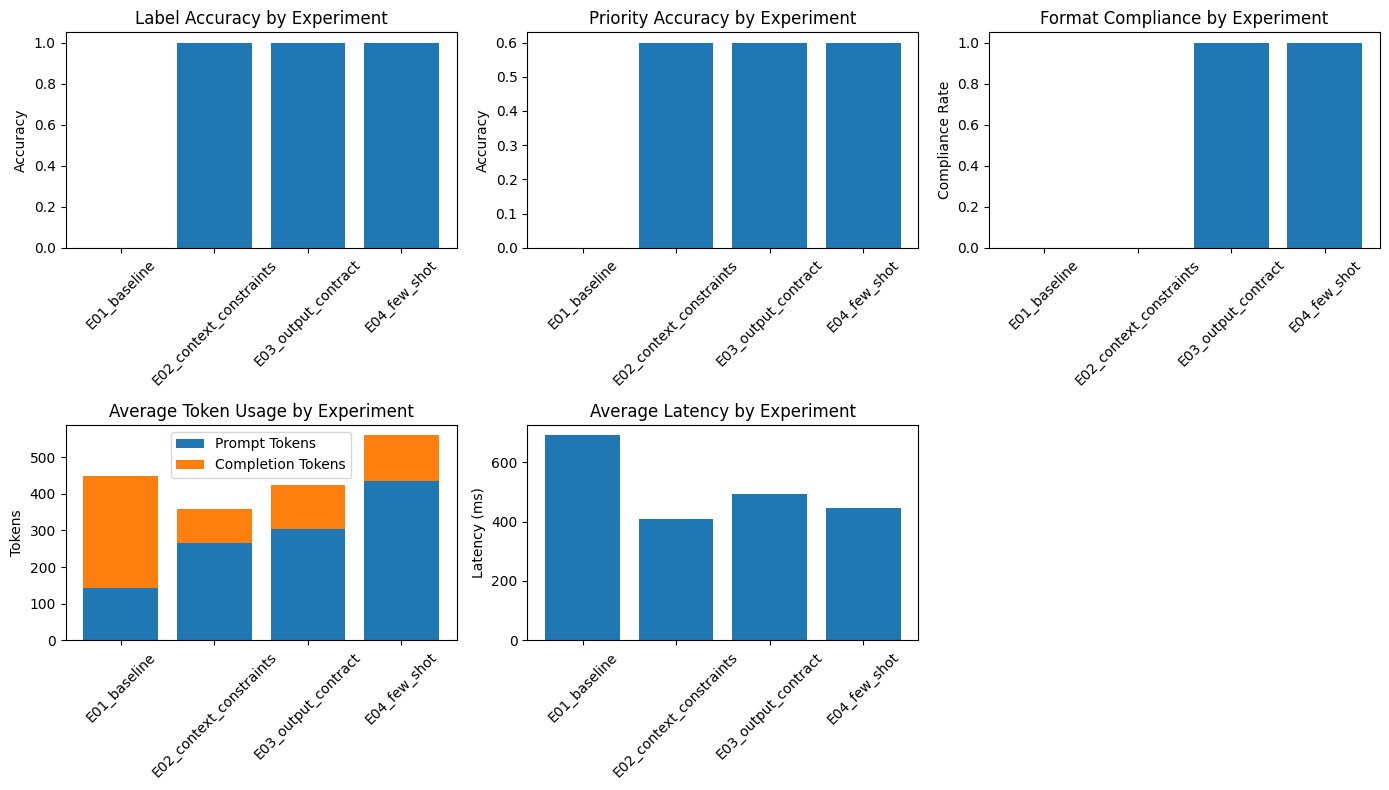

In [14]:
if not df_comparison.empty:
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))

    axes[0, 0].bar(df_comparison["experiment"], df_comparison["label_accuracy"])
    axes[0, 0].set_title("Label Accuracy by Experiment")
    axes[0, 0].set_ylabel("Accuracy")
    axes[0, 0].tick_params(axis="x", rotation=45)

    axes[0, 1].bar(df_comparison["experiment"], df_comparison["priority_accuracy"])
    axes[0, 1].set_title("Priority Accuracy by Experiment")
    axes[0, 1].set_ylabel("Accuracy")
    axes[0, 1].tick_params(axis="x", rotation=45)

    axes[0, 2].bar(df_comparison["experiment"], df_comparison["format_compliance_rate"])
    axes[0, 2].set_title("Format Compliance by Experiment")
    axes[0, 2].set_ylabel("Compliance Rate")
    axes[0, 2].tick_params(axis="x", rotation=45)

    axes[1, 0].bar(df_comparison["experiment"], df_comparison["avg_prompt_tokens"], label="Prompt Tokens")
    axes[1, 0].bar(
        df_comparison["experiment"],
        df_comparison["avg_completion_tokens"],
        bottom=df_comparison["avg_prompt_tokens"],
        label="Completion Tokens",
    )
    axes[1, 0].set_title("Average Token Usage by Experiment")
    axes[1, 0].set_ylabel("Tokens")
    axes[1, 0].tick_params(axis="x", rotation=45)
    axes[1, 0].legend()

    axes[1, 1].bar(df_comparison["experiment"], df_comparison["avg_latency_ms"])
    axes[1, 1].set_title("Average Latency by Experiment")
    axes[1, 1].set_ylabel("Latency (ms)")
    axes[1, 1].tick_params(axis="x", rotation=45)

    axes[1, 2].axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Gorsellestirme icin once Step 7'de RUN_LIVE = True yaparak deneyleri calistirin.")


## Step 11 — Tartisma

Yukaridaki sonuclari calistirdiktan sonra asagidaki sorulari tartisin.
Olcum yapilmadan (yani `RUN_LIVE = True` ile deneyler calistirilmadan) bu
sorulara verilecek cevaplar sadece spekulasyondur — sonuc uydurmayin, gercek
`df_comparison` tablosuna bakarak cevaplayin.

1. Hangi prompt en yuksek accuracy degerine ulasti?
2. Output Contract (`E03_output_contract`) format uyumunu nasil etkiledi?
3. Few-shot ornekleri (`E04_few_shot`) performansi iyilestirdi mi?
4. En fazla token hangi deneyde kullanildi?
5. Daha uzun prompt gercekten daha basarili mi? Hipotezimizi dogruluyor mu?
